In [7]:
import math
import numpy as mp

In [8]:
class Value:
    def __init__(self,data,child=(),label='',op=''):
        self.data=data
        self.prev=set(child)
        self.label=label
        self.op=op
        self.grad=0.0
        self._backward=lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data+other.data,(self,other),op='+')

        def backward():
            self.grad+=out.grad
            other.grad+=out.grad
            
        out._backward=backward

        return out
    
    def __radd__(self, other): # a fallback when the passed args wont match the expected in add function
        return self+other
    
    def __neg__(self):
        return self*-1
    
    def __sub__(self, other):
        return self+(-other)
    
    def __mul__(self, other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data*other.data,(self,other),op='*')

        def backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad     

        out._backward=backward

        return out

    def __rmul__(self, other):
        return self*other

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out=Value(self.data**other,(self,),op='pow')
    
        def backward():
            self.grad+=out.grad*(other*(self.data**(other-1)))
    
        out._backward=backward
        
        return out
    
    def __truediv__(self, other):
        return self*(other**-1)

    def exp(self):
        x=math.exp(self.data)
        out=Value(x,(self,),op='exp')

        def backward():
            self.grad+=out.grad*out.data

        out._backward=backward

        return out

    def tanh(self):
        t=math.tanh(self.data)
    
        out=Value(t,(self,),op='tanh')
    
        def backward():
            self.grad+=(1-t**2)*out.grad
    
        out._backward=backward
    
        return out
    
    def backprop(self):
        topo=[]
        visited=set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                        
                for child in v.prev:
                    build_topo(child)
            
                topo.append(v)

        build_topo(self)

        self.grad=1
        for node in reversed(topo):
            node._backward()

In [9]:
x1=Value(4.0,label='x1')
x2=Value(5.0,label='x2')

w1=Value(1.0,label='w1')
w2=Value(2.0,label='w2')

w1x1=w1*x1
w1x1.label='w1x1'

w2x2=w2*x2
w2x2.label='w2x2'

b=Value(2,label='b')

t=w1x1+w2x2
t.label='t'

s=t+b
s.label='s'

e=(2*s).exp()
e.label='e'

o=(e-1)/(e+1)
o.label='o'


In [10]:
print(x1*1,1*x1)

Value(data=4.0) Value(data=4.0)


In [11]:
print(f"w1.grad > {w1.grad}")
print(f"w2.grad > {w2.grad}")
print(f"x1.grad > {x1.grad}")
print(f"x2.grad > {x2.grad}")
print(f"w1x1.grad > {w1x1.grad}")
print(f"w2x2.grad > {w2x2.grad}")
print(f"t.grad > {t.grad}")
print(f"b.grad > {b.grad}")
print(f"s.grad > {s.grad}")
print(f"o.grad > {o.grad}")

o.backprop()
print("\n")

print(f"w1.grad > {w1.grad}")
print(f"w2.grad > {w2.grad}")
print(f"x1.grad > {x1.grad}")
print(f"x2.grad > {x2.grad}")
print(f"w1x1.grad > {w1x1.grad}")
print(f"w2x2.grad > {w2x2.grad}")
print(f"t.grad > {t.grad}")
print(f"b.grad > {b.grad}")
print(f"s.grad > {s.grad}")
print(f"o.grad > {o.grad}")

w1.grad > 0.0
w2.grad > 0.0
x1.grad > 0.0
x2.grad > 0.0
w1x1.grad > 0.0
w2x2.grad > 0.0
t.grad > 0.0
b.grad > 0.0
s.grad > 0.0
o.grad > 0.0


w1.grad > 2.0232049322358337e-13
w2.grad > 2.529006165294792e-13
x1.grad > 5.058012330589584e-14
x2.grad > 1.0116024661179169e-13
w1x1.grad > 5.058012330589584e-14
w2x2.grad > 5.058012330589584e-14
t.grad > 5.058012330589584e-14
b.grad > 5.058012330589584e-14
s.grad > 5.058012330589584e-14
o.grad > 1


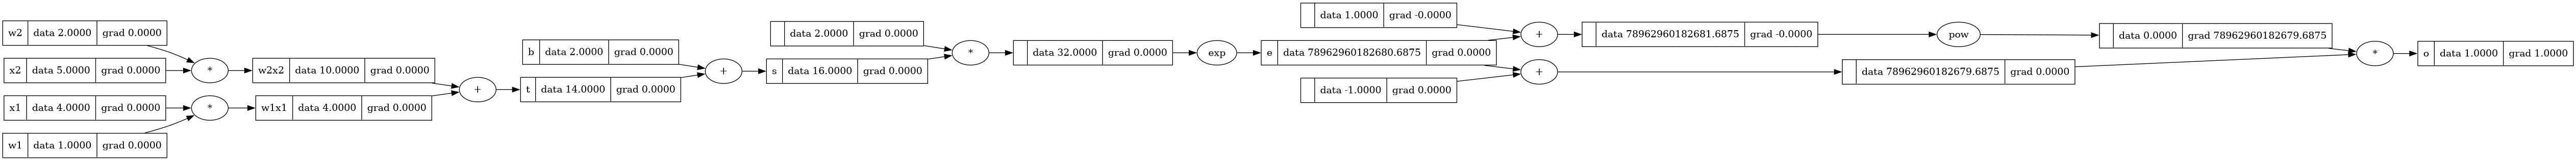

In [12]:
import math
from graphviz import Digraph
from IPython.display import Image, display

def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def get_op(n):
    """Return the real op symbol of a node ('' for leaf nodes)."""
    if n.op:
        return n.op
    if not n.prev:
        return ''
    if n.label in ('+', '*'):
        return n.label
    # label was overwritten (e.g. 'x1*w1'), so infer from the data
    kids = list(n.prev)
    if len(kids) == 2:
        a, b = kids[0].data, kids[1].data
        if math.isclose(a + b, n.data):
            return '+'
        if math.isclose(a * b, n.data):
            return '*'
    elif len(kids) == 1:          # x + x or x * x
        a = kids[0].data
        if math.isclose(a + a, n.data):
            return '+'
        if math.isclose(a * a, n.data):
            return '*'
    return '?'

def get_label(n):
    """Hide '+' / '*' if they were wrongly stored as the label."""
    return '' if n.label in ('+', '*') and n.prev else n.label

def draw_dot(root, rankdir="LR"):
    dot = Digraph(format="png", graph_attr={"rankdir": rankdir})
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        op = get_op(n)

        # value box: label | data | grad
        dot.node(
            uid,
            label=f"{{ {get_label(n)} | data {n.data:.4f} | grad {n.grad:.4f} }}",
            shape="record",
        )

        # op oval with just the symbol
        if op:
            dot.node(uid + op, label=op)
            dot.edge(uid + op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + get_op(n2))

    display(Image(dot.pipe(format="png")))

draw_dot(o)